# simulating lineage growth scenarios 

           scenario  p_divide  p_stay  p_die  m_E_X  Var_X  mu_fit  sigma_fit  \
0   Same m, low Var      0.15    0.80   0.05   1.10  0.190   1.113      0.590   
1      Higher death      0.35    0.25   0.40   0.95  0.747   1.477      0.557   
2  Same m, high Var      0.45    0.20   0.35   1.10  0.790   2.170      0.557   
3          Baseline      0.35    0.40   0.25   1.10  0.590   1.933      0.553   
4       Lower death      0.35    0.55   0.10   1.25  0.387   2.575      0.500   

   n_lineages  median_size  
0       37500            3  
1        6808            4  
2       14553            7  
3       18364            6  
4       36208           11  


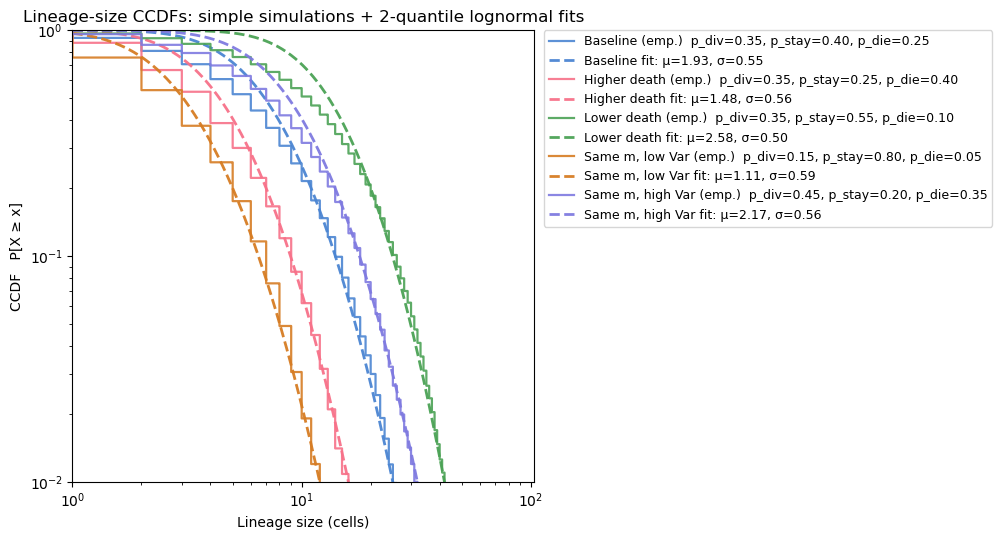

In [1]:
# --- imports ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm


# ---------- helper: empirical "higher" quantile ----------
def q_higher(x, p):
    """Smallest order statistic >= p (works well for integer data)."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        raise ValueError("Empty data.")
    x.sort()
    idx = int(np.ceil(p * x.size)) - 1
    idx = min(max(idx, 0), x.size - 1)
    return x[idx]

# ---------- 2-quantile lognormal fit ----------
def fit_lognormal_two_quantiles(sizes, p1=0.80, p2=0.99, min_size=1):
    x = np.asarray(sizes, float)
    x = x[x >= min_size]
    if x.size < 5:
        raise ValueError("Too few points ≥ min_size.")
    q1, q2 = q_higher(x, p1), q_higher(x, p2)
    z1, z2 = norm.ppf(p1), norm.ppf(p2)
    if q1 <= 0 or q2 <= 0 or q2 == q1:
        raise ValueError("Quantiles degenerate; adjust p1/p2 or min_size.")
    sigma = (np.log(q2) - np.log(q1)) / (z2 - z1)
    mu = np.log(q1) - sigma * z1
    return float(mu), float(abs(sigma))

# ---------- CCDF helpers ----------
def empirical_ccdf(x_all):
    xs = np.sort(np.asarray(x_all, float))
    ccdf = 1.0 - np.arange(1, len(xs) + 1) / len(xs)
    return xs, ccdf

def lognormal_ccdf(x, mu, sigma):
    z = (np.log(x) - mu) / sigma
    return 1.0 - norm.cdf(z)


# ---------- simple simulator: outcomes {0,1,2} only ----------
def simulate_lineages_minimal(
    n_initial_cells=50_000,
    n_steps=10,
    p_divide=0.35,
    p_die=0.25,
    rng_seed=42
):
    """
    Per step per cell: 0 (die) with p_die, 1 (stay) with p_stay, 2 (divide) with p_divide.
    Vectorized two-stage update:
      survivors ~ Binomial(counts, s)          with s = 1 - p_die
      divides   ~ Binomial(survivors, q)       with q = p_divide / s   (if s>0 else 0)
      counts'   = survivors + divides
    Returns final_sizes (extinct lineages dropped) and None for TS (kept minimal).
    """
    assert 0 <= p_divide <= 1 and 0 <= p_die <= 1 and p_divide + p_die <= 1, "invalid probabilities"
    rng = np.random.default_rng(rng_seed)
    counts = np.ones(n_initial_cells, dtype=np.int64)

    s = 1.0 - p_die
    q = (p_divide / s) if s > 0 else 0.0
    q = min(max(q, 0.0), 1.0)

    for _ in range(n_steps):
        if counts.sum() == 0:
            break
        survivors = rng.binomial(counts, s) if s > 0 else np.zeros_like(counts)
        divides   = rng.binomial(survivors, q) if q > 0 else np.zeros_like(survivors)
        counts    = survivors + divides

    final_sizes = counts[counts > 0]
    return final_sizes, None


# ---------- five simple scenarios (no bursts) ----------
def make_simple_cases():
    return [
        dict(name="Baseline",         p_divide=0.35, p_die=0.25),  # m=1.10
        dict(name="Higher death",     p_divide=0.35, p_die=0.40),  # m=0.95
        dict(name="Lower death",      p_divide=0.35, p_die=0.10),  # m=1.25
        dict(name="Same m, low Var",  p_divide=0.15, p_die=0.05),  # m=1.10
        dict(name="Same m, high Var", p_divide=0.45, p_die=0.35),  # m=1.10
    ]


# ---------- runner: empirical solid + fit dashed (same color), legend outside ----------
def run_and_plot_5_simple_cases(
    n_initial_cells=1000,
    n_steps=10,
    quantiles=(0.80, 0.99),   # same p1,p2 as your empirical analysis
    min_size=1,
    seed_base=100,
    cases=None,
    x_max=1e3,
    y_min=1e-4
):
    cases = make_simple_cases() if cases is None else cases
    colors = ["#4b85d2", "#f77189", "#4ba255", "#d67c23", "#7f7ae0"]

    fig, ax = plt.subplots(figsize=(7.5, 5.5))
    records = []

    for i, sc in enumerate(cases):
        sizes, _ = simulate_lineages_minimal(
            n_initial_cells=n_initial_cells,
            n_steps=n_steps,
            p_divide=sc["p_divide"],
            p_die=sc["p_die"],
            rng_seed=seed_base + i + 1,
        )
        if sizes.size == 0:
            continue

        p_div = sc["p_divide"]
        p_die = sc["p_die"]
        p_stay = max(0.0, 1.0 - p_die - p_div)
        m   = p_stay + 2*p_div
        ex2 = p_stay + 4*p_div
        varX = ex2 - m*m

        # empirical CCDF (solid step)
        xs, ccdf = empirical_ccdf(sizes)
        emp_label = (f"{sc['name']} (emp.)  "
                     f"p_div={p_div:.2f}, p_stay={p_stay:.2f}, p_die={p_die:.2f}")
        ax.step(xs, ccdf, where="post", lw=1.6, alpha=0.9, color=colors[i], label=emp_label)

        # 2-quantile lognormal fit (dashed, same color)
        mu_fit, sigma_fit = fit_lognormal_two_quantiles(
            sizes, p1=quantiles[0], p2=quantiles[1], min_size=min_size
        )
        xg = np.logspace(np.log10(max(1, xs.min())), np.log10(xs.max()), 500)
        ax.plot(xg, lognormal_ccdf(xg, mu_fit, sigma_fit),
                linestyle="--", lw=2.0, alpha=0.95, color=colors[i],
                label=f"{sc['name']} fit: μ={mu_fit:.2f}, σ={sigma_fit:.2f}")

        # summary row
        records.append(dict(
            scenario=sc["name"],
            p_divide=p_div, p_stay=round(p_stay, 3), p_die=p_die,
            m_E_X=round(m, 3), Var_X=round(varX, 3),
            mu_fit=round(mu_fit, 3), sigma_fit=round(sigma_fit, 3),
            n_lineages=int(sizes.size), median_size=int(np.median(sizes))
        ))

    # axes, grid, legend outside
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(1,)
    ax.set_ylim(1e-2,1)
    ax.set_xlabel("Lineage size (cells)")
    ax.set_ylabel("CCDF   P[X ≥ x]")
    ax.set_title("Lineage-size CCDFs: simple simulations + 2-quantile lognormal fits")
    ax.grid(False)
    fig.tight_layout(rect=[0, 0, 0.75, 1])
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), borderaxespad=0.0, fontsize=9)

    summary = pd.DataFrame.from_records(records).sort_values("sigma_fit", ascending=False).reset_index(drop=True)
    return summary, (fig, ax)


# ---------- example usage ----------
if __name__ == "__main__":
    SUM, _ = run_and_plot_5_simple_cases(
        n_initial_cells=50_000,
        n_steps=10,
        quantiles=(0.80, 0.99),   # same as your empirical
        min_size=1,
        seed_base=100,
        x_max=1e3,
        y_min=1e-4
    )
    print(SUM)
    plt.savefig("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/simulated_lineages_sizes.pdf", bbox_inches="tight")
    plt.show()
